# Método de Gauss–Seidel
Sistema: 10x − y + 2z = 6; −x + 11y − z = 22; 2x − y + 10z = −10

In [ ]:
# Imports
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [ ]:
# Dados do problema
A = np.array([[10, -1,  2],
              [-1, 11, -1],
              [ 2, -1, 10]], dtype=float)
b = np.array([6, 22, -10], dtype=float)
x0 = np.zeros(3)          # aproximação inicial (0, 0, 0)
tol = 1e-5                # critério de parada: ||x^(k) - x^(k-1)||_inf < 1e-5

In [ ]:
# Questão 2: dominância diagonal por linhas
for i in range(3):
    diag = abs(A[i, i])
    fora = np.sum(np.abs(A[i])) - diag
    print(f"Linha {i+1}: |a_ii| = {diag:.0f} > soma dos demais = {fora:.0f} ? {diag > fora}")

In [ ]:
# Questão 5: implementação do método de Gauss-Seidel
def gauss_seidel(A, b, x0, tol=1e-5, max_iter=1000):
    n = len(b)
    x = x0.astype(float).copy()
    historico = [(0, *x, np.nan)]          # k = 0 (sem erro definido)
    for k in range(1, max_iter + 1):
        x_ant = x.copy()
        for i in range(n):
            # usa valores já atualizados (j < i) e valores antigos (j > i)
            soma = A[i, :i] @ x[:i] + A[i, i+1:] @ x_ant[i+1:]
            x[i] = (b[i] - soma) / A[i, i]
        erro = np.max(np.abs(x - x_ant))   # norma infinito
        historico.append((k, *x, erro))
        if erro < tol:
            break
    return x, k, historico

x_sol, n_iter, hist = gauss_seidel(A, b, x0, tol)

print(f"\nNúmero de iterações: {n_iter}")
print(f"Solução aproximada: x = {x_sol[0]:.8f}, y = {x_sol[1]:.8f}, z = {x_sol[2]:.8f}")
print(f"Solução exata (numpy): {np.linalg.solve(A, b)}")

In [ ]:
# Questão 6: tabela das iterações
df = pd.DataFrame(hist, columns=["k", "x(k)", "y(k)", "z(k)", "||x(k)-x(k-1)||_inf"])
df["k"] = df["k"].astype(int)
pd.options.display.float_format = "{:.8f}".format
try:
    display(df)          # Colab/Jupyter
except NameError:
    print(df.to_string(index=False))

In [ ]:
# Questão 7a: x, y, z em função de k
plt.figure(figsize=(8, 5))
plt.plot(df["k"], df["x(k)"], "o-", label="x(k)")
plt.plot(df["k"], df["y(k)"], "s-", label="y(k)")
plt.plot(df["k"], df["z(k)"], "^-", label="z(k)")
plt.xlabel("Iteração k"); plt.ylabel("Valor aproximado")
plt.title("Evolução das aproximações - Gauss-Seidel")
plt.grid(True, alpha=0.3); plt.legend()
plt.savefig("grafico_aproximacoes.png", dpi=150, bbox_inches="tight")
plt.show()

In [ ]:
# Questão 7b: erro entre iterações (escala log)
plt.figure(figsize=(8, 5))
plt.semilogy(df["k"][1:], df["||x(k)-x(k-1)||_inf"][1:], "o-", color="crimson", label="erro")
plt.axhline(tol, color="gray", linestyle="--", label="tolerância 1e-5")
plt.xlabel("Iteração k"); plt.ylabel(r"$\|x^{(k)}-x^{(k-1)}\|_\infty$")
plt.title("Erro entre iterações (escala logarítmica)")
plt.grid(True, which="both", alpha=0.3); plt.legend()
plt.savefig("grafico_erro.png", dpi=150, bbox_inches="tight")
plt.show()

## Resolução manuscrita (questões 1 a 4)

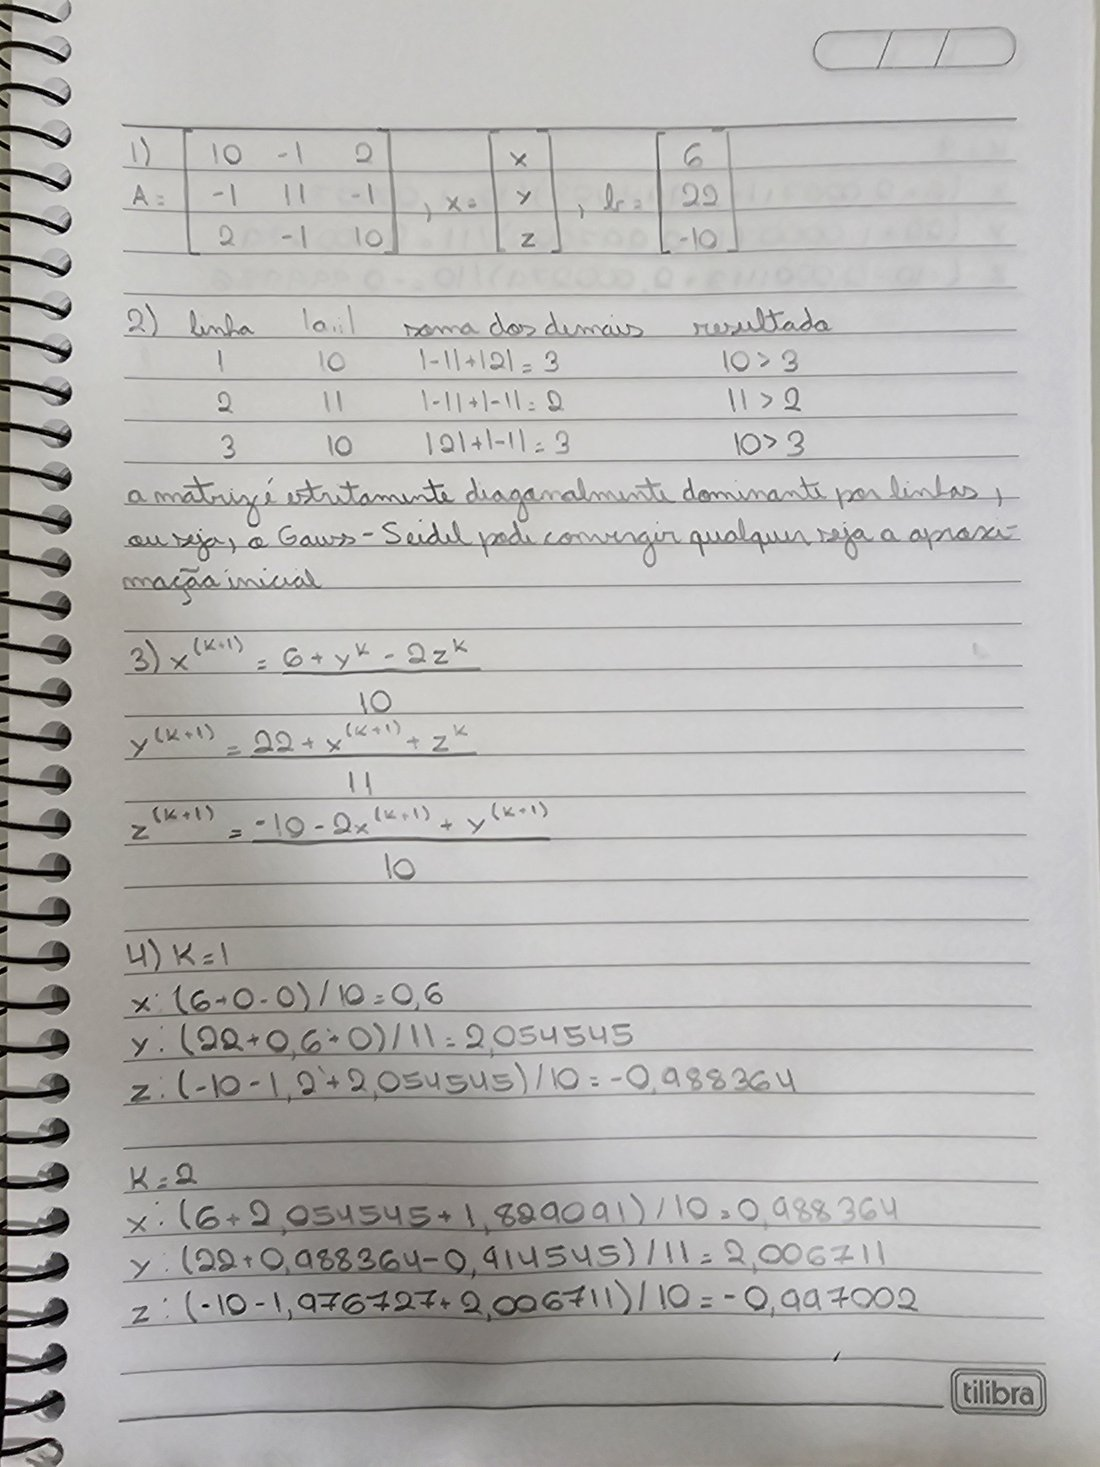

In [ ]:
# Página 1 do caderno (imagem embutida na saída desta célula)

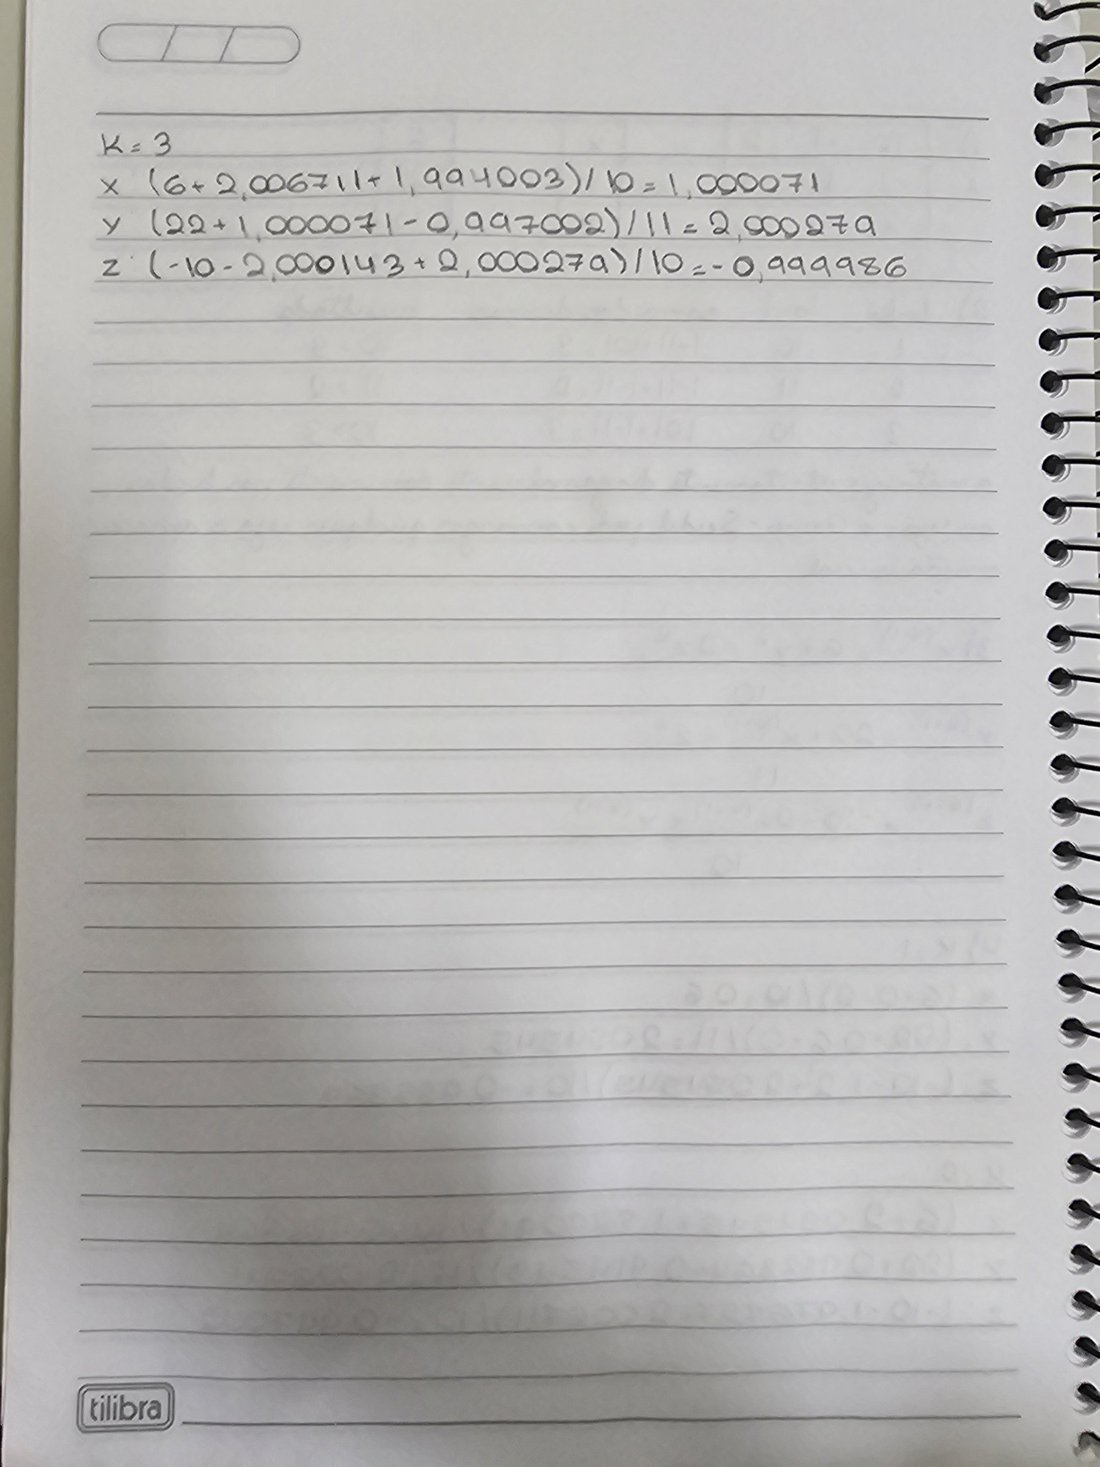

In [ ]:
# Página 2 do caderno (imagem embutida na saída desta célula)